In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from pathlib import Path
from sklearn.metrics import (accuracy_score,f1_score,precision_score,recall_score,classification_report)
from src.ModelA_init import build_model
from src.data_preparation import OCTMNISTDataPreprocessor
from src.ModelB_init import build_model as build_modelB

In [2]:
SEED = 42
EPOCHS = 20
BATCH_SIZE = 64

In [3]:
Path("results").mkdir(exist_ok=True)

In [4]:
preprocessor=OCTMNISTDataPreprocessor(data_path="../data/octmnist_64.npz")
X_train,X_val, X_test, y_train, y_val, y_test = preprocessor.load_dataset()

Loading OCTMNIST data...
Original splits loaded: Training Datapoints: 97477, Validation Datapoints: 10832, Test Datapoints: 1000
Total Data Points: 109309
Creating new stratified splits...
New splits created: Training Datapoints: 76516, Validation Datapoints: 16396, Test Datapoints: 16397
Shapes of returned Splits: X_train: (76516, 64, 64, 1), X_val: (16396, 64, 64, 1), X_test: (16397, 64, 64, 1)
Shapes of returned Labels: y_train: (76516,), y_val: (16396,), y_test: (16397,)


In [5]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

In [6]:
ModelA=build_model(verbose=True)
ModelA.summary()


Model A: Standard CNN with Dropout


Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution1 (Conv2D)           │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1 (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution2 (Conv2D)           │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling2 (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution3 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling3 (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution4 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling4 (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SpatialDropout                  │ (None, 4, 4, 256)      │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseHidden (Dense)             │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseDropout (Dropout)          │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,196 (1.51 MB)

 Trainable params: 396,196 (1.51 MB)

...

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution1 (Conv2D)           │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1 (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution2 (Conv2D)           │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling2 (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution3 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling3 (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution4 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling4 (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SpatialDropout                  │ (None, 4, 4, 256)      │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseHidden (Dense)             │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseDropout (Dropout)          │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,196 (1.51 MB)

 Trainable params: 396,196 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Compile the model
ModelA.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

In [8]:
history_adam_001 = ModelA.fit(X_train,y_train,validation_data=(X_val, y_val),batch_size=64,epochs=20,shuffle=True,verbose=1)

Epoch 1/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 40s 33ms/step - accuracy: 0.7632 - loss: 0.6471 - val_accuracy: 0.8730 - val_loss: 0.3683
Epoch 2/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 40s 33ms/step - accuracy: 0.8987 - loss: 0.3080 - val_accuracy: 0.9268 - val_loss: 0.2237
Epoch 3/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 40s 34ms/step - accuracy: 0.9241 - loss: 0.2348 - val_accuracy: 0.9350 - val_loss: 0.2019
Epoch 4/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 39s 33ms/step - accuracy: 0.9364 - loss: 0.1984 - val_accuracy: 0.9446 - val_loss: 0.1729
Epoch 5/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 40s 33ms/step - accuracy: 0.9443 - loss: 0.1747 - val_accuracy: 0.9474 - val_loss: 0.1599
Epoch 6/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 35ms/step - accuracy: 0.9491 - loss: 0.1594 - val_accuracy: 0.9522 - val_loss: 0.1483
Epoch 7/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 40s 33ms/step - accuracy: 0.9534 - loss: 0.1445 - val_accuracy: 0.9477 - val_loss: 0.1591
Epoch 8/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 40s 33ms/step - accuracy: 0.9574 -

In [9]:
val_probs = ModelA.predict(X_val, batch_size=256, verbose=0)
val_pred = np.argmax(val_probs, axis=1)
val_true = np.asarray(y_val).reshape(-1)

print("Macro Precision:", precision_score(
    val_true, val_pred, average="macro", zero_division=0
))

print("Macro Recall:", recall_score(
    val_true, val_pred, average="macro", zero_division=0
))

print("Macro F1:", f1_score(
    val_true, val_pred, average="macro", zero_division=0
))

print("Macro Accuracy:", accuracy_score(
    val_true, val_pred
))

print("\nClassification Report:")
print(classification_report(
    val_true,
    val_pred,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

Macro Precision: 0.9285412341922313
Macro Recall: 0.928736899742229
Macro F1: 0.9283774249011562
Macro Accuracy: 0.9567577457916565

Classification Report:
              precision    recall  f1-score   support

         CNV       0.96      0.98      0.97      5618
         DME       0.96      0.92      0.94      1740
      Drusen       0.81      0.85      0.83      1330
      Normal       0.98      0.97      0.97      7708

    accuracy                           0.96     16396
   macro avg       0.93      0.93      0.93     16396
weighted avg       0.96      0.96      0.96     16396



**Observing Validation Metrics it is clear that the model is overfitting. The model is performing well on the training data but poorly on the validation data. This indicates that the model has learned to memorize the training data rather than generalizing to unseen data.**

In [10]:
#Implementing LR scheduler to reduce learning rate on plateau
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

In [11]:
ModelA = build_model(verbose=False)

ModelA.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

ModelA.summary()

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution1 (Conv2D)           │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1 (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution2 (Conv2D)           │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling2 (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution3 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling3 (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution4 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling4 (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SpatialDropout                  │ (None, 4, 4, 256)      │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseHidden (Dense)             │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseDropout (Dropout)          │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,196 (1.51 MB)

 Trainable params: 396,196 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Reduce learning rate when validation loss stops improving
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=3,min_delta=0.001,min_lr=1e-5,mode="min",verbose=1)
# Save weights from the epoch with lowest validation loss
checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath="results/model_a_adaptive_lr.weights.h5",monitor="val_loss",save_best_only=True,save_weights_only=True,mode="min",verbose=1)
history_adaptive_adam_001 = ModelA.fit(X_train,y_train,validation_data=(X_val, y_val),epochs=20,batch_size=64,shuffle=True,callbacks=[lr_scheduler, checkpoint],verbose=1)

Epoch 1/20
1195/1196 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7632 - loss: 0.6473 
Epoch 1: val_loss improved from None to 0.36829, saving model to results/model_a_adaptive_lr.weights.h5

Epoch 1: finished saving model to results/model_a_adaptive_lr.weights.h5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 33ms/step - accuracy: 0.7632 - loss: 0.6471 - val_accuracy: 0.8730 - val_loss: 0.3683 - learning_rate: 0.0010
Epoch 2/20
1195/1196 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8987 - loss: 0.3080 
Epoch 2: val_loss improved from 0.36829 to 0.22368, saving model to results/model_a_adaptive_lr.weights.h5

Epoch 2: finished saving model to results/model_a_adaptive_lr.weights.h5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.8987 - loss: 0.3080 - val_accuracy: 0.9268 - val_loss: 0.2237 - learning_rate: 0.0010
Epoch 3/20
1195/1196 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9241 - loss: 0.2348 
Epoch 3: val_loss improved from 0.22368 to 0.20193, saving model to results/model

In [13]:
val_probs = ModelA.predict(X_val, batch_size=256, verbose=0)
val_pred = np.argmax(val_probs, axis=1)
val_true = np.asarray(y_val).reshape(-1)

print("Macro Precision:", precision_score(
    val_true, val_pred, average="macro", zero_division=0
))

print("Macro Recall:", recall_score(
    val_true, val_pred, average="macro", zero_division=0
))

print("Macro F1:", f1_score(
    val_true, val_pred, average="macro", zero_division=0
))

print("Macro Accuracy:", accuracy_score(
    val_true, val_pred
))

print("\nClassification Report:")
print(classification_report(
    val_true,
    val_pred,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

Macro Precision: 0.9398971385974253
Macro Recall: 0.9328948010666676
Macro F1: 0.9363456934896991
Macro Accuracy: 0.9632837277384728

Classification Report:
              precision    recall  f1-score   support

         CNV       0.97      0.97      0.97      5618
         DME       0.96      0.94      0.95      1740
      Drusen       0.85      0.83      0.84      1330
      Normal       0.98      0.98      0.98      7708

    accuracy                           0.96     16396
   macro avg       0.94      0.93      0.94     16396
weighted avg       0.96      0.96      0.96     16396



In [14]:
best_model = build_model(verbose=False)

best_model.load_weights(
    "results/model_a_adaptive_lr.weights.h5"
)

best_probs = best_model.predict(
    X_val,
    batch_size=256,
    verbose=0
)

best_preds = np.argmax(best_probs, axis=1)
val_true = np.asarray(y_val).reshape(-1)

print("Best Checkpoint Macro-F1:",
      f1_score(
          val_true,
          best_preds,
          average="macro",
          zero_division=0
      ))

print(classification_report(
    val_true,
    best_preds,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

Best Checkpoint Macro-F1: 0.9307788956552048
              precision    recall  f1-score   support

         CNV       0.98      0.96      0.97      5618
         DME       0.95      0.95      0.95      1740
      Drusen       0.81      0.84      0.83      1330
      Normal       0.98      0.98      0.98      7708

    accuracy                           0.96     16396
   macro avg       0.93      0.93      0.93     16396
weighted avg       0.96      0.96      0.96     16396



In [15]:
ModelB=build_modelB(verbose=True)
ModelB.summary()


Model B: Lightweight CNN with Dropout


Model: "Model_B_Lightweight_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SeparableConv1                  │ (None, 64, 64, 32)     │            73 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1 (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SeparableConv2                  │ (None, 32, 32, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling2 (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SeparableConv3                  │ (None, 16, 16, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling3 (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SeparableConv4                  │ (None, 8, 8, 256)      │        34,176 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling4 (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SpatialDropout                  │ (None, 4, 4, 256)      │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseHidden (Dense)             │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseDropout (Dropout)          │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,901 (210.55 KB)

 Trainable params: 53,901 (210.55 KB)

...

Model: "Model_B_Lightweight_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SeparableConv1                  │ (None, 64, 64, 32)     │            73 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1 (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SeparableConv2                  │ (None, 32, 32, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling2 (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SeparableConv3                  │ (None, 16, 16, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling3 (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SeparableConv4                  │ (None, 8, 8, 256)      │        34,176 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling4 (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SpatialDropout                  │ (None, 4, 4, 256)      │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseHidden (Dense)             │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseDropout (Dropout)          │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,901 (210.55 KB)

 Trainable params: 53,901 (210.55 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Compile the model
ModelB.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)
# Reduce learning rate when validation loss stops improving
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=3,min_delta=0.001,min_lr=1e-5,mode="min",verbose=1)
# Save weights from the epoch with lowest validation loss
checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath="results/model_b_adaptive_lr.weights.h5",monitor="val_loss",save_best_only=True,save_weights_only=True,mode="min",verbose=1)
history_adaptive_adam_001_B = ModelB.fit(X_train,y_train,validation_data=(X_val, y_val),epochs=20,batch_size=64,shuffle=True,callbacks=[lr_scheduler, checkpoint],verbose=1)

Epoch 1/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5837 - loss: 1.0095 
Epoch 1: val_loss improved from None to 0.72078, saving model to results/model_b_adaptive_lr.weights.h5

Epoch 1: finished saving model to results/model_b_adaptive_lr.weights.h5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.5837 - loss: 1.0095 - val_accuracy: 0.7416 - val_loss: 0.7208 - learning_rate: 0.0010
Epoch 2/20
1193/1196 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7495 - loss: 0.7056 
Epoch 2: val_loss improved from 0.72078 to 0.64043, saving model to results/model_b_adaptive_lr.weights.h5

Epoch 2: finished saving model to results/model_b_adaptive_lr.weights.h5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - accuracy: 0.7495 - loss: 0.7056 - val_accuracy: 0.7669 - val_loss: 0.6404 - learning_rate: 0.0010
Epoch 3/20
1194/1196 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7892 - loss: 0.6079 
Epoch 3: val_loss improved from 0.64043 to 0.53096, saving model to results/model

In [17]:
val_probs = ModelB.predict(X_val, batch_size=256, verbose=0)
val_pred = np.argmax(val_probs, axis=1)
val_true = np.asarray(y_val).reshape(-1)

print("Macro Precision:", precision_score(
    val_true, val_pred, average="macro", zero_division=0
))

print("Macro Recall:", recall_score(
    val_true, val_pred, average="macro", zero_division=0
))

print("Macro F1:", f1_score(
    val_true, val_pred, average="macro", zero_division=0
))

print("Macro Accuracy:", accuracy_score(
    val_true, val_pred
))

print("\nClassification Report:")
print(classification_report(
    val_true,
    val_pred,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

Macro Precision: 0.8899697033343019
Macro Recall: 0.8633742203845187
Macro F1: 0.8757223073907502
Macro Accuracy: 0.929434008294706

Classification Report:
              precision    recall  f1-score   support

         CNV       0.94      0.96      0.95      5618
         DME       0.94      0.84      0.89      1740
      Drusen       0.72      0.69      0.70      1330
      Normal       0.95      0.97      0.96      7708

    accuracy                           0.93     16396
   macro avg       0.89      0.86      0.88     16396
weighted avg       0.93      0.93      0.93     16396



In [18]:
best_model = build_modelB(verbose=False)

best_model.load_weights(
    "results/model_b_adaptive_lr.weights.h5"
)

best_probs = best_model.predict(
    X_val,
    batch_size=256,
    verbose=0
)

best_preds = np.argmax(best_probs, axis=1)
val_true = np.asarray(y_val).reshape(-1)

print("Best Checkpoint Macro-F1:",
      f1_score(
          val_true,
          best_preds,
          average="macro",
          zero_division=0
      ))

print(classification_report(
    val_true,
    best_preds,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

Best Checkpoint Macro-F1: 0.8757223073907502
              precision    recall  f1-score   support

         CNV       0.94      0.96      0.95      5618
         DME       0.94      0.84      0.89      1740
      Drusen       0.72      0.69      0.70      1330
      Normal       0.95      0.97      0.96      7708

    accuracy                           0.93     16396
   macro avg       0.89      0.86      0.88     16396
weighted avg       0.93      0.93      0.93     16396



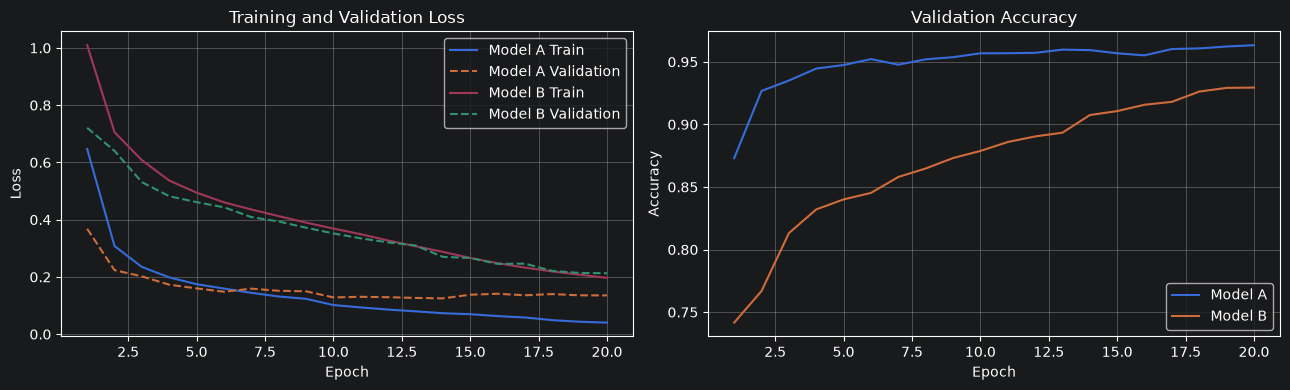

In [19]:
import matplotlib.pyplot as plt

histories = {
    "Model A": history_adaptive_adam_001,
    "Model B": history_adaptive_adam_001_B
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, history in histories.items():

    epochs = range(1, len(history.history["loss"]) + 1)

    axes[0].plot(
        epochs,
        history.history["loss"],
        label=f"{name} Train"
    )

    axes[0].plot(
        epochs,
        history.history["val_loss"],
        linestyle="--",
        label=f"{name} Validation"
    )

    axes[1].plot(
        epochs,
        history.history["val_accuracy"],
        label=name
    )

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [20]:
from pathlib import Path

# Create directories
Path("results/models").mkdir(parents=True, exist_ok=True)
Path("results/weights").mkdir(parents=True, exist_ok=True)
Path("results/histories").mkdir(parents=True, exist_ok=True)

# Save complete models
ModelA.save("results/models/model_a_final.keras")
ModelB.save("results/models/model_b_final.keras")

# Save weights separately
ModelA.save_weights("results/weights/model_a_final.weights.h5")
ModelB.save_weights("results/weights/model_b_final.weights.h5")

print("Both models saved successfully!")

Both models saved successfully!
